# Exercise 6.1
This exercise uses data which is obtained from the books own code. The code KS.m is run in Matlab to create the dataset for the Kuramoto Sivinshinky equation.

It also uses the data obtained from running the reaction_diffusion_rhs.m and reaction_diffusion.m files which solves the reaction diffusion equation.

All codes have been run prior and the data obtained from all, are saved in the data folder.


In [1]:
# Import necessary libraries and modules
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from scipy.io import loadmat
from keras.models import Sequential     # It was chosen to use the Sequential model for building the neural networks
from keras.layers import Dense, Input
from sklearn.preprocessing import StandardScaler # Recommended by Copilot for standardizing the data before training the neural network
import random
import copy
random.seed(42) # Set random seed for reproducibility

### (a)
A neural network should be trained on the KS dataset obtained from the codebase. Initially the data is imported.

In [ ]:
# Load train data
data = loadmat("CODE/kuramoto_sivishinky.mat")

After the data has been loaded, the training data is split up into input, x, and output, y, components. As the NN should be able to advance the solution from time t to t + dt, the data is split up such that y(t) = x(t+dt).
In order to do this the solution field, u(t), is used. This means the NN should forecast the field at each spatial position for the next timestep, given the field at each spatial position of the current timestep.

In [3]:
""" Create the input and output training data """
# Only load the solution field data and transpose it to have the correct shape (snapshot, spatial position)
train = data['uu'].T

# Create the input and output data by shifting the training data by one time step such that y[i, :] = x[i+1, :]
x_train = train[:-1]
y_train = train[1:]

# Obtain dimensions of the training data
n_rows_x, n_features = x_train.shape
n_rows_y, n_features_y = y_train.shape

# Make sure training and test have same number of features
assert n_features == n_features_y

print(f"Training data shape: {x_train.shape}, {y_train.shape}")

Training data shape: (250, 1024), (250, 1024)


After the training data has been structured, and the input and output arrays have been created, the structure of the feedforward NN is made. It is chosen to use the Sequential model from the keras library, as this allows for a simple model contruction. The Dense layers are used, as these construct simple fully connected layers.

In [6]:
""" Create the feedforward NN model using keras Dense layers """ 
model = Sequential()
model.add(Input(shape=(n_features,))) # 1024 input features (spatial positions)
# The network consits of 2 hidden layers with 100 neurons each, both using relu activation.
# This is chosen somewhat arbitrarily with some trial and error.
model.add(Dense(units=100, activation="relu"))
model.add(Dense(units=100, activation="relu"))
# A final layer with linear actiavtion is used to predict the final output.
model.add(Dense(n_features))
# Mean squared error is used af loss function and the adam optimizer is used for training.
model.compile(loss='mean_squared_error', optimizer='adam')

After the network has been created, it is trained on the training data. It is chosen to use an epoch size, the number of times the training algorithm should do a complete pass of the training data, of 500.

This choice, together with the number of layers, number of neurons in each layer, choice of activation etc. are all parameters that could be tweaked using validation datasets, to construct a better and more robust NN.

In [7]:
# Train the model using keras fit method.
model.fit(x_train, y_train, epochs=500)

Epoch 1/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.0794  
Epoch 2/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7519 
Epoch 3/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4927 
Epoch 4/500
1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3653

error: operand #1 does not dominate this use
W0000 00:00:1794057091.054187  257534 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
error: operand #0 does not dominate this use
W0000 00:00:1794057091.136872  257534 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3376 
Epoch 5/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2361 
Epoch 6/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1689 
Epoch 7/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1253
Epoch 8/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0981 
Epoch 9/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0802
Epoch 10/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0669
Epoch 11/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0567 
Epoch 12/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0478 
Epoch 13/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0399
Epoch 14/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0341
Epoch 15/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0288 
Epoch 16/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0249 
Epoch 17/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0217
Epoch 18/500
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0190 
Epoch 19/500
8/8 ━━━━━━━━━━━━━━━━━

After the model has been trained, it is interesting to try it on the data it was trained on. This is done as a sanity check to show that the model can actually predict the training data.

Here model is not actually forecasting, as it is using the actual values from the solution.

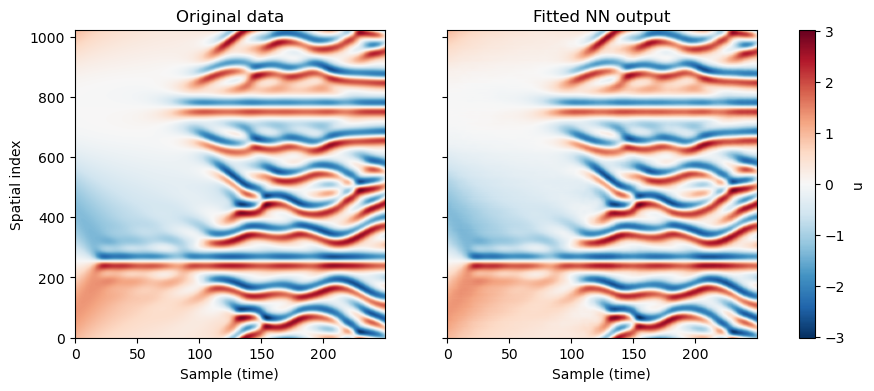

In [12]:
""" Plot training dataset (plots have been created using Copilot)"""
# Compare the fitted output with the original target data.
y_train_pred = model.predict(x_train, verbose=0)

vmax = np.max(np.abs(y_train))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

im = axes[0].imshow(y_train.T, aspect="auto", origin="lower",
                    cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[0].set_title("Original data")

axes[1].imshow(y_train_pred.T, aspect="auto", origin="lower",
               cmap="RdBu_r", vmin=-vmax, vmax=vmax)
axes[1].set_title("Fitted NN output")

for ax in axes:
    ax.set_xlabel("Sample (time)")
axes[0].set_ylabel("Spatial index")

fig.colorbar(im, ax=axes, label="u")
plt.show()

It is seen that given the correct input data, the NN is able to fit the output data on the dataset it was trained on. This is however not what the intention of the model was.

It should now be tested if the model is actually able to forecast the trajectory on its own.

### (b)

To test the NN's ability to forecast the KS equation the model is tested on the training set, however where only one initital value is given to the NN, whereafter it uses its own predictions to forecast the trajectory.

The NN is tested using 4 different starting points, initial conditions, on the dataset. For each starting point it will predict the next solution value, which is then saved, and fed back to the model to predict the next value. Thereby, the NN model will forecast the entire solution model only using one initial value as input.

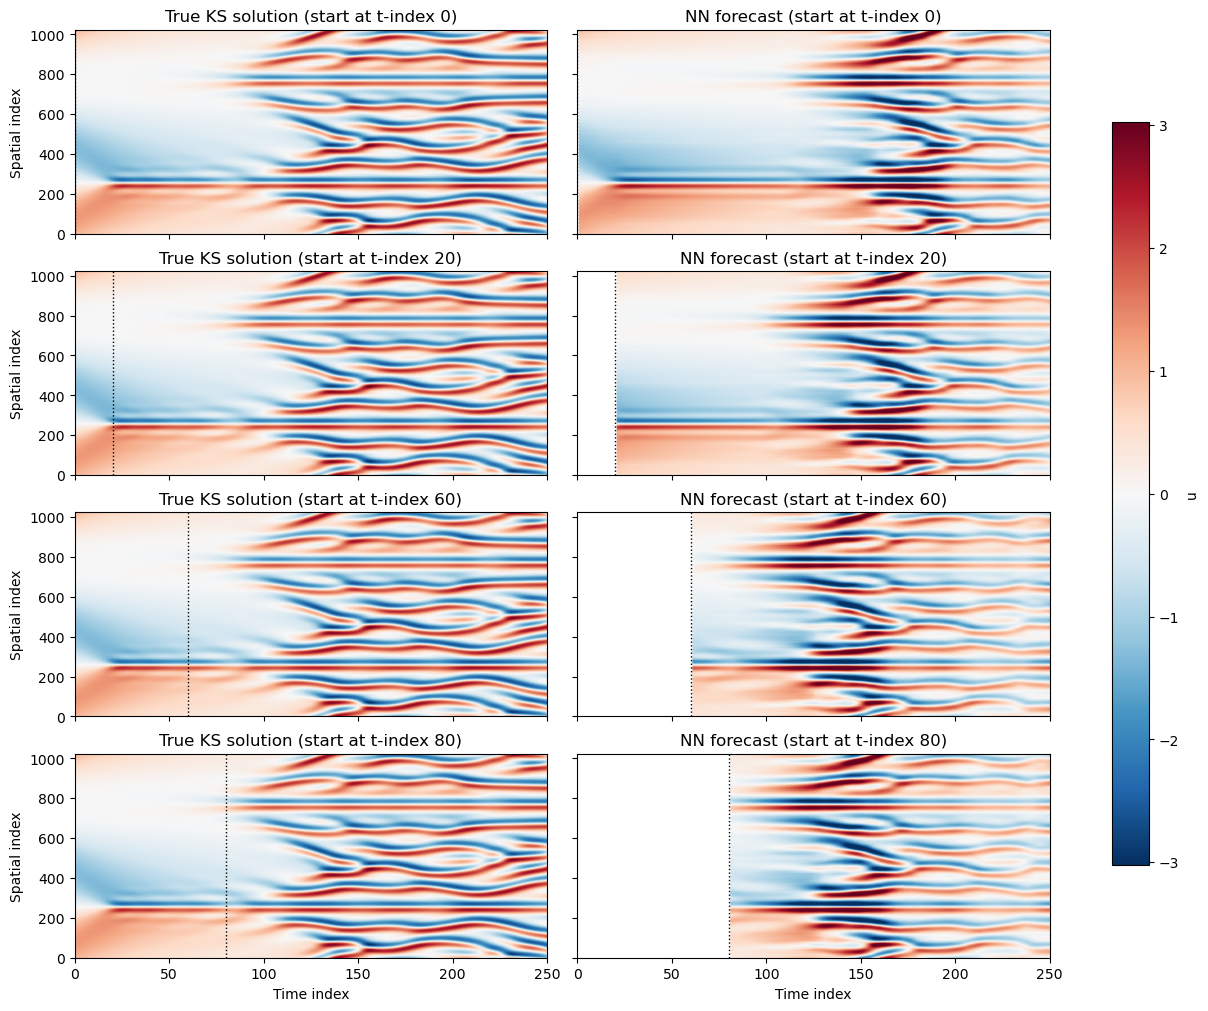

In [13]:
""" Testing network on different initial conditions """

# Four different starting points are chosen.
starting_points = [0, 20, 60, 80]

# Copilot has been used to create the plotting code.
n_time = len(x_train)

# One symmetric color scale shared by every panel
vmax = np.max(np.abs(x_train))

# Colormap where NaN (no prediction yet) is drawn as white
cmap = copy.copy(plt.get_cmap("RdBu_r"))
cmap.set_bad("white")

fig, axes = plt.subplots(len(starting_points), 2, figsize=(12, 10),
                         sharex=True, sharey=True, constrained_layout=True)

# Loop over each starting point
for row, i in zip(axes, starting_points):
    # Autoregressive forecast from starting index i
    current = x_train[i].copy().reshape(1, n_features)
    forecast = []
    # Create entire forecasting trajectory only using one true initial point
    for k in range(n_time - i - 1):
        next_state = model.predict(current, verbose=0)
        forecast.append(next_state[0])
        current = next_state
    forecast = np.array(forecast)

    # forecast[k] is the prediction for time index i+k+1.
    # Full-length array: NaN everywhere before the forecast begins.
    forecast_full = np.full_like(x_train, np.nan, dtype=float)
    forecast_full[i + 1:] = forecast

    extent = [0, n_time, 0, n_features]

    im = row[0].imshow(x_train.T, aspect="auto", origin="lower", extent=extent,
                       cmap=cmap, vmin=-vmax, vmax=vmax)
    row[1].imshow(forecast_full.T, aspect="auto", origin="lower", extent=extent,
                  cmap=cmap, vmin=-vmax, vmax=vmax)

    # Mark the starting point on both panels
    for ax in row:
        ax.axvline(i, color="k", linestyle=":", linewidth=1)

    row[0].set_title(f"True KS solution (start at t-index {i})")
    row[1].set_title(f"NN forecast (start at t-index {i})")
    row[0].set_ylabel("Spatial index")

for ax in axes[-1]:
    ax.set_xlabel("Time index")

fig.colorbar(im, ax=axes, label="u", shrink=0.8)
plt.show()

The plots show that the NN performs worse during recursive forecasting than in one-step prediction, where the actual current state is provided at each step. This is likely because the prediction errors accumulate and can grow as the predictions are fed back as input.

The NN is however, still able to somewhat represent the flow pattern. It is seen that generally the NN does not capture the amplitude of the pattern very well. It overestimates the amplitude of the fluctuations between 100-150 and underestimates the amplitudes of the last fluctuations. It is also seen that the network predicts the start of oscillations later, than the true trajectory.

To improve the model its hyperparameters could be tuned furhter using validation sets. Here one could perhaps include the forecasting ability, to actually train the NN on forecasting, instead of one-step prediction.

One could also test the NN on a test set, where the time steps where perhaos different, to see how its forecasting abilities change with differing dts.

### (c)
The forecasting method is now tested on the reaction-diffusion dataset. Becuase of the shear size of the dataset, the dimension reduction tools which were explored in week 1, SVD analysis, are used, to reduce its size. 



In [14]:
# Loading in the reaction_diffusion dataset
data_rd = loadmat("CODE/reaction_diffusion_big.mat")

# Check what's inside
print(data_rd.keys())

dict_keys(['__header__', '__version__', '__globals__', 't', 'u', 'v', 'x', 'y'])


After the dataset has been loaded, the relevant data is obtained, u-velocity, and it is reshaped to a 2D array.
When the data has been reshaped, the numpy method linalg.svd is used to perform the singular value decomposition, which is used to reduce the size of the dataset.

In [15]:
# Export relevant data
u = data_rd["u"]
t = data_rd["t"]
nx, ny, nt = u.shape

# Flattens the velocity for each timestep
u = u.reshape(nx * ny, nt)

# Generate SVD from data points
Uhat, Shat, VThat = np.linalg.svd(u, full_matrices=False)

After the SVD matricies are found, three different ranks are found for testing the forecasting possibility. Here the relative error of each r-rank SVD approximation is found, and the ranks needed to account for 90, 99 and 99.9 % of the flow are used.

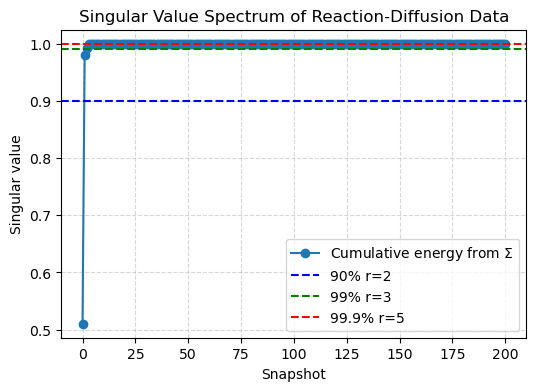

In [16]:
""" Used to find possible ranks to test """
# The same code as used in Exercise 1.7 is used.
# Find cumulative energy for plot using Frobenius norm
energy_cum = np.cumsum(Shat**2) / np.sum(Shat**2)

# Find ranks for 90, 99 and 99.9 % of captured flow:
r90 = np.argmax(energy_cum >= 0.90) + 1
r99 = np.argmax(energy_cum >= 0.99) + 1
r999 = np.argmax(energy_cum >= 0.999) + 1

# Print singular value spectrum
plt.figure(figsize=(6, 4))
plt.plot(energy_cum, 'o-', label = r"Cumulative energy from $\Sigma$")
plt.axhline(0.9, color = 'b', linestyle = '--', label=f"90% r={r90}")
plt.axhline(0.99, color = 'g', linestyle = '--', label=f"99% r={r99}")
plt.axhline(0.999, color = 'r', linestyle = '--', label=f"99.9% r={r999}")
plt.xlabel("Snapshot")
plt.ylabel("Singular value")
plt.legend()
plt.title("Singular Value Spectrum of Reaction-Diffusion Data")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

From the relative error analysis it is decided to test the 2-, 3- and 5-rank SVD approximation of the reaction-diffusion system. For each rank, a separate model is trained and evaluated, using the first 70% of the snapshots for training and the remaining 30% for testing.

Rather than predicting the full state matrix (X), each model is trained to predict the reduced coefficient matrix:
$$
A_r=\hat{\Sigma}_r V_r^\mathsf{T}
$$
This matrix contains the reduced coordinates for one snapshot. From this, the full state can be approximated as:
$$
X \approx \hat{U}_r A_r
$$

This reduces the output dimension the network must learn while hopefully retaining the significant patterns in the data.

In [18]:
# Using the found ranks
r = [2, 3, 5]
train_time = int(nt*0.7) # Use 70% of snapshots for training
train_list = []
test_list = []
model_list = []

# Loop over each rank and train a model for each
for i in r:
    A = np.diag(Shat[:i]) @ VThat[:i, :] # Compose the low-rank approximation
    A = A.transpose() # Transpose to have snapshots in the rows
    
    # Create the training and testing data
    train = A[:train_time]
    test = A[train_time:]
    train_list.append(train)
    test_list.append(test)

    # Create the input and output training data
    x_train = train[:-1]
    y_train = train[1:]
    
    # Create the NN model for each rank
    model = Sequential()
    model.add(Input(shape=(i,))) # The number of features depends on the rank
    # Two dense layer using 100 neurons and relu activation
    model.add(Dense(100, activation="relu")) 
    model.add(Dense(100, activation="relu"))
    model.add(Dense(i)) # Linear output layer
    model.compile(loss="mean_squared_error", optimizer="adam")
    
    # Train the model using 100 epochs
    model.fit(x_train, y_train, epochs=100, verbose = 0)
    
    model_list.append(model)

error: operand #1 does not dominate this use
W0000 00:00:1794059179.768736  257534 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
error: operand #0 does not dominate this use
W0000 00:00:1794059179.849163  257534 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
error: operand #1 does not dominate this use
W0000 00:00:1794059181.596485  257534 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
error: operand #0 does not dominate this use
W0000 00:00:1794059181.671416  257534 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
error: operand #1 does not dominate this use
W0000 00:00:1794059183.373917  257534 optimize_function_graph_utils

The three trained models are plotted against the training data, using one-step prediction.

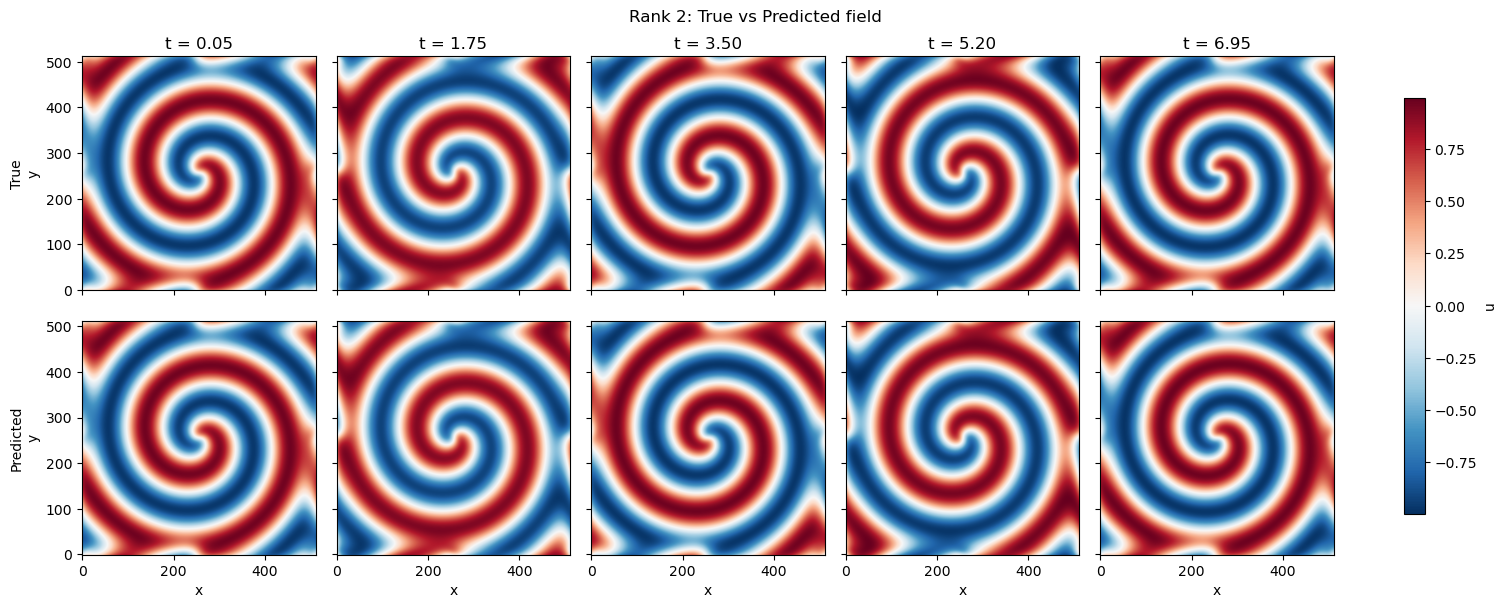

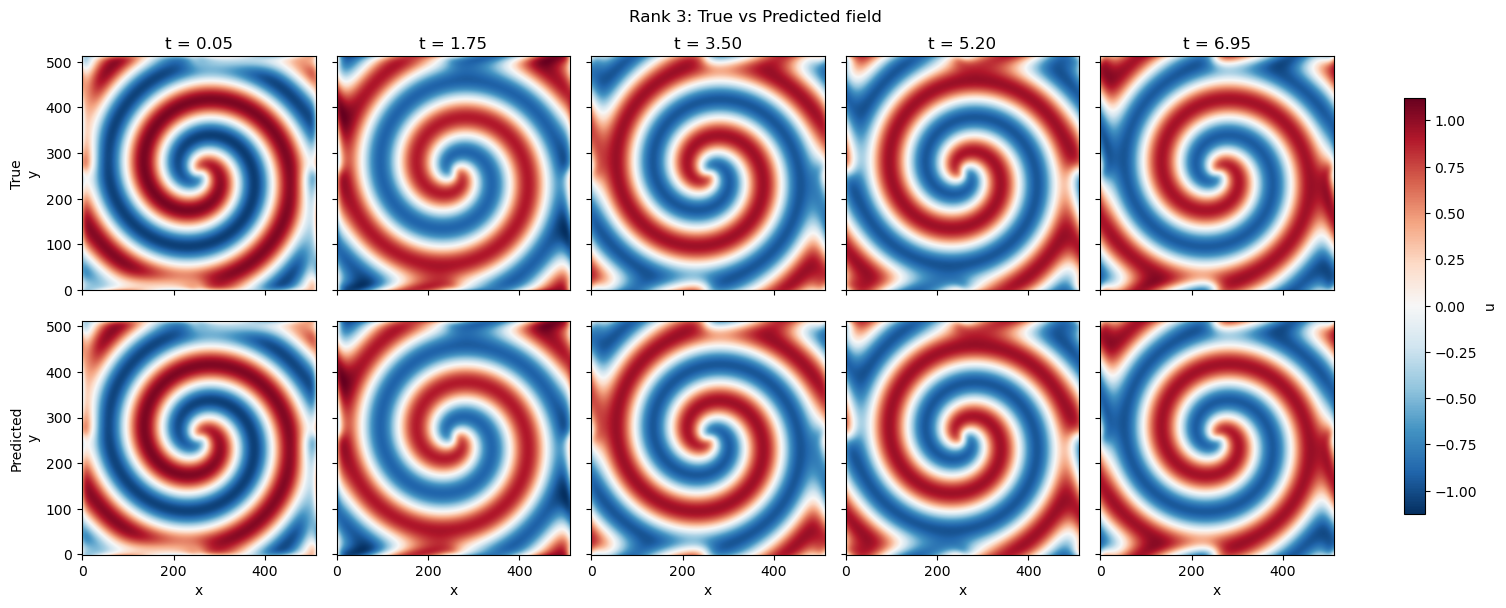

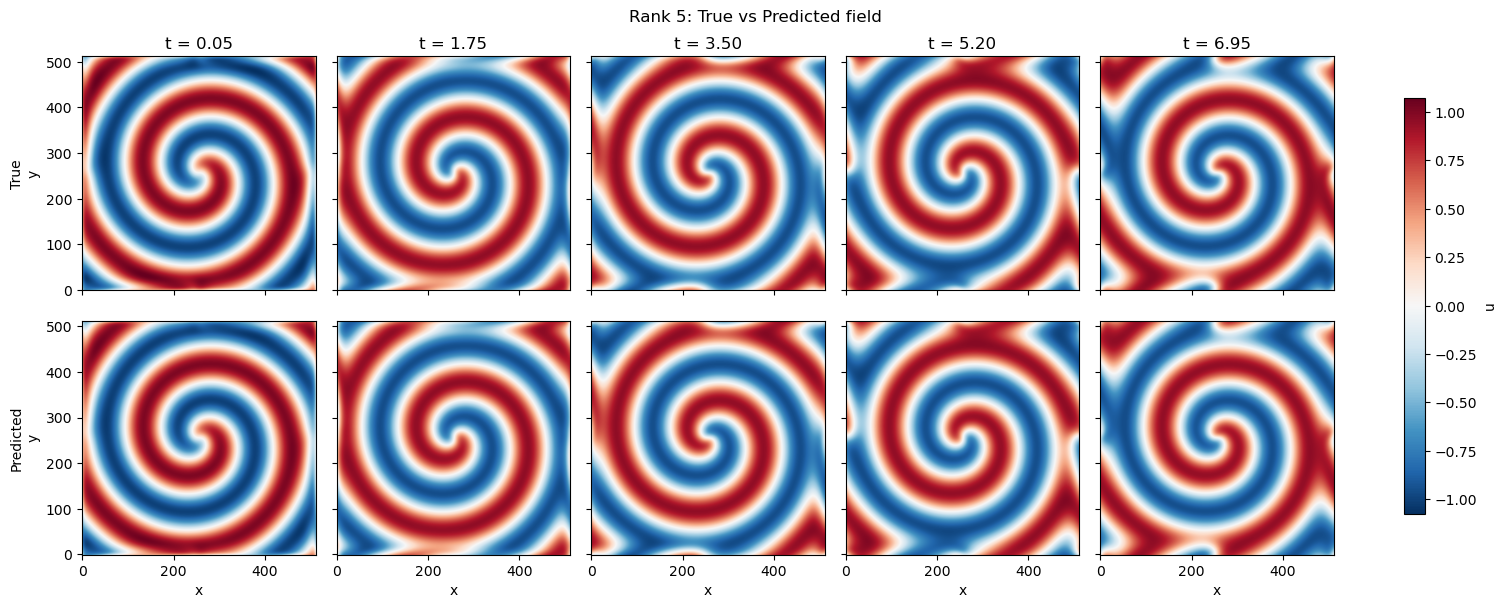

In [20]:
# Testing on the training dataset to see if the model can do one-step prediction on it
y_train_pred_list = [np.asarray(model(train[:-1], training=False))
    for model, train in zip(model_list, train_list)]

# Plot true vs predicted
snap_idx = np.linspace(1, train_time - 1, 5, dtype=int)   # time indices to show
t_vals = t.flatten()

for j, rank in enumerate(r):
    Ur = Uhat[:, :rank]                                    # (nx*ny, rank)

    # Back from reduced coefficients to the full spatial field
    true_full = train_list[j] @ Ur.T                       # (train_time, nx*ny)
    pred_full = y_train_pred_list[j] @ Ur.T                # (train_time, nx*ny)

    vmax = np.max(np.abs(true_full))                       # shared symmetric color scale

    fig, axes = plt.subplots(2, len(snap_idx), figsize=(3 * len(snap_idx), 6),
                             sharex=True, sharey=True, constrained_layout=True)

    for col, k in enumerate(snap_idx):
        # pred_full[k-1] is the model's prediction for time index k
        im = axes[0, col].imshow(true_full[k].reshape(nx, ny).T, origin="lower",
                                 cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        axes[1, col].imshow(pred_full[k - 1].reshape(nx, ny).T, origin="lower",
                            cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        axes[0, col].set_title(f"t = {t_vals[k]:.2f}")

    axes[0, 0].set_ylabel("True\ny")
    axes[1, 0].set_ylabel("Predicted\ny")
    for ax in axes[1]:
        ax.set_xlabel("x")

    fig.suptitle(f"Rank {rank}: True vs Predicted field")
    fig.colorbar(im, ax=axes, label="u", shrink=0.8)
    plt.show()

Each model shows its ability to do one-step prediction on the data it has been trained on. Now the forecasting ability is tested on test data.
Here the same forecasting structure is used, as for the KS equation.

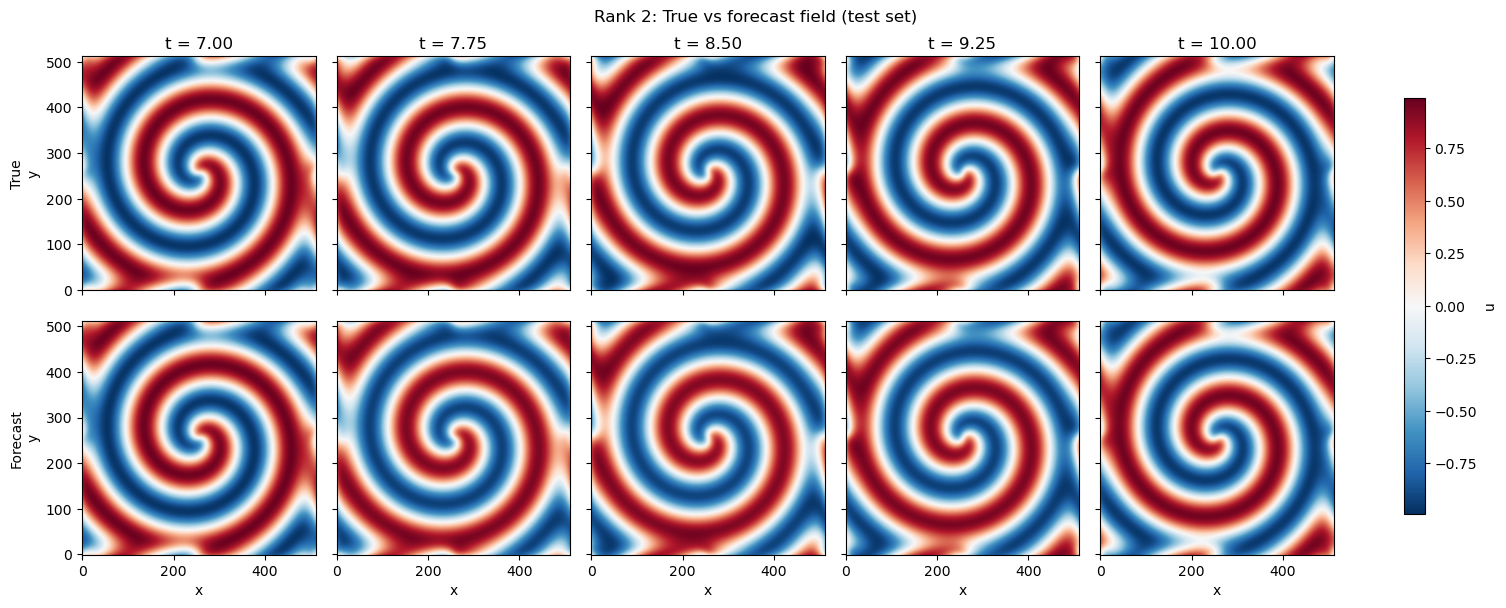

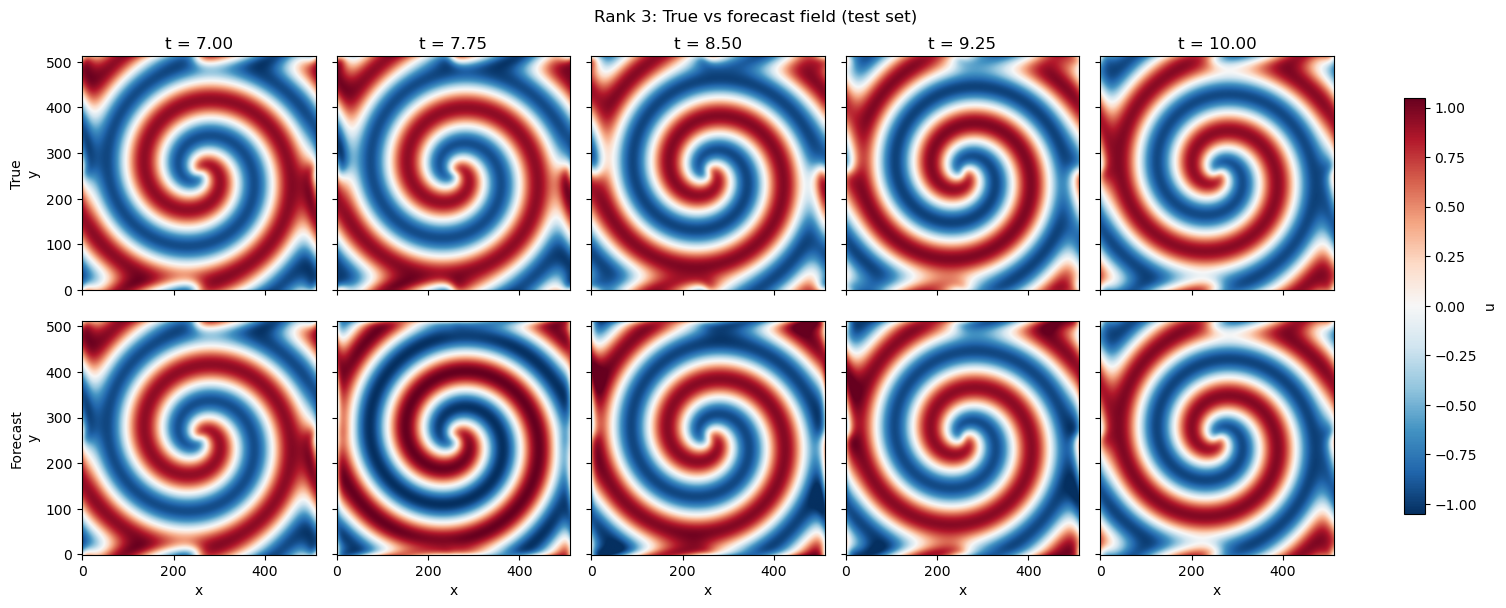

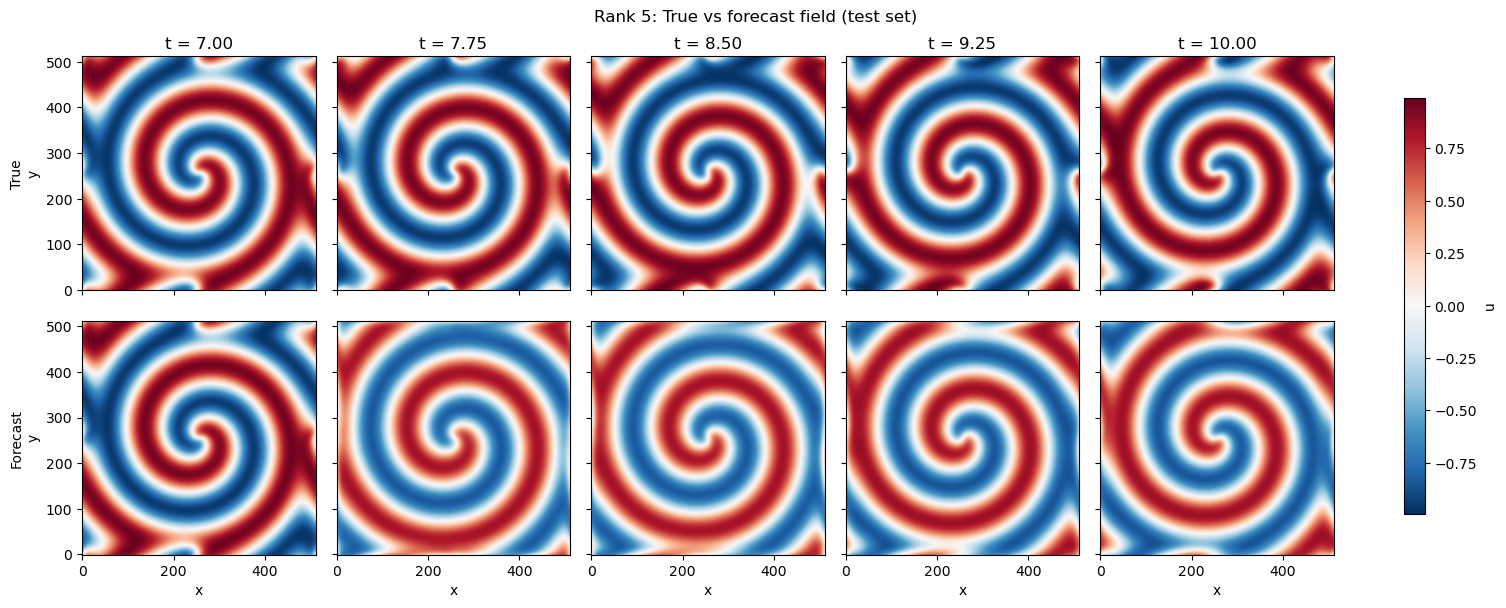

In [21]:
# Copilot have assisted in creating the plotting structure

n_test = nt - train_time
snap_idx = np.linspace(0, n_test - 1, 5, dtype=int)   # indices within the test window

for j, rank in enumerate(r):
    Ur = Uhat[:, :rank]

    # Autoregressive rollout in reduced space, starting from the first test state
    current = test_list[j][0].reshape(1, rank)
    forecast = [current[0]]                            # index 0 = known initial condition
    for k in range(n_test - 1):
        current = model_list[j].predict(current, verbose=0)
        forecast.append(current[0])
    forecast = np.array(forecast)                      # (n_test, rank), aligned with test_list[j]

    # Back to the full spatial field
    true_full = test_list[j] @ Ur.T                    # (n_test, nx*ny)
    pred_full = forecast @ Ur.T

    vmax = np.max(np.abs(true_full))                   # shared symmetric color scale

    fig, axes = plt.subplots(2, len(snap_idx), figsize=(3 * len(snap_idx), 6),
                             sharex=True, sharey=True, constrained_layout=True)

    for col, k in enumerate(snap_idx):
        im = axes[0, col].imshow(true_full[k].reshape(nx, ny).T, origin="lower",
                                 cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        axes[1, col].imshow(pred_full[k].reshape(nx, ny).T, origin="lower",
                            cmap="RdBu_r", vmin=-vmax, vmax=vmax)
        axes[0, col].set_title(f"t = {t_vals[train_time + k]:.2f}")

    axes[0, 0].set_ylabel("True\ny")
    axes[1, 0].set_ylabel("Forecast\ny")
    for ax in axes[1]:
        ax.set_xlabel("x")

    fig.suptitle(f"Rank {rank}: True vs forecast field (test set)")
    fig.colorbar(im, ax=axes, label="u", shrink=0.8)
    plt.show()

The plot indicates that the NN using only 2-ranks is closest to the actual trajectory of A.

It is seen that the NN is able to do forecasting and follow the trajectory. The trajectory of the testing data also nicely follows the trend seen in the training data for all three models, which probably improves the NN abilities, e.g. compared to the KS equation above, where the dynamics were not as smooth and regular.

### (d)

Now the Lorenz equation is evaluated. Here forecasting using NN is also tested, where the model is trained on three datasets and tested on two new ones. Both the training and testing datasets are generated using code from the lectures slides from week 2. Copilot has been used to translate the data creation code from Matlab to python.

100 random trajectories for each rho are created.
During training and construction of the NN, it was decided to scale the input and output parameters, as this was able to improve the performance of the NN. Here the StandardScaler function from sklearn is used.

In [22]:
# Simulation parameters
dt = 0.01
T = 4
t = np.arange(0, T + dt, dt)

b = 8 / 3
sigma = 10
rho_train = [10, 28, 40]
rho_test = [17, 35]

n_trajectories_per_rho = 100

# Lorenz system
def lorenz(t, x, rho):
    return [
        sigma * (x[1] - x[0]),
        rho * x[0] - x[0] * x[2] - x[1],
        x[0] * x[1] - b * x[2],
    ]

# Generate training data
rng = np.random.default_rng()
inputs_train = []
outputs_train = []
rho_per_trajectory = []

inputs_test = []
outputs_test = []

for rho in rho_train:
    for _ in range(n_trajectories_per_rho):
        x0 = 30 * (rng.random(3) - 0.5)
        solution = solve_ivp(
            lorenz,
            (t[0], t[-1]),
            x0,
            t_eval=t,
            rtol=1e-10,
            atol=1e-11,
            args=(rho,),
        )

        # Shape: (number of time points, 3)
        y = solution.y.T

        inputs_train.append(y[:-1])
        outputs_train.append(y[1:])
        rho_per_trajectory.append(rho)


for rho in rho_test:
    x0 = 30 * (rng.random(3) - 0.5)
    solution = solve_ivp(
        lorenz,
        (t[0], t[-1]),
        x0,
        t_eval=t,
        rtol=1e-10,
        atol=1e-11,
        args=(rho,)
    )

    # Shape: (number of time points, 3)
    y = solution.y.T

    inputs_test.append(y[:-1])
    outputs_test.append(y[1:])

input_train = np.concatenate(inputs_train, axis=0)
output_train = np.concatenate(outputs_train, axis=0)

# Standardize the training data using StandardScaler from sklearn.preprocessing
x_scaler_lorenz = StandardScaler()
y_scaler_lorenz = StandardScaler()

X_lorenz = x_scaler_lorenz.fit_transform(input_train)
Y_lorenz = y_scaler_lorenz.fit_transform(output_train)

# Obtain dimensions of the training data
n_rows_x_lorenz, n_features_lorenz = input_train.shape
n_rows_y_lorenz, n_features_y_lorenz = output_train.shape

assert n_features_lorenz == n_features_y_lorenz

print(X_lorenz.shape)
print(Y_lorenz.shape)


(120000, 3)
(120000, 3)


After the datasets are created, an NN is constructed and trained on the three training dataset, which are combined in the input_train and output_train. 100 epochs are used for training.

In [24]:
""" Create the feedforward NN model using keras Dense layers """ 
model = Sequential()
model.add(Input(shape=(n_features_lorenz,)))
model.add(Dense(50, activation="sigmoid"))
model.add(Dense(50, activation="sigmoid"))
model.add(Dense(50, activation="linear"))
# A final layer with linear actiavtion is used to predict the final output.
model.add(Dense(n_features_lorenz))
# Mean squared error is used af loss function and the adam optimizer is used for training.
model.compile(loss='mean_squared_error', optimizer='adam')

# Train the model using keras fit method.
model.fit(X_lorenz, Y_lorenz, epochs=100)

Epoch 1/100
 133/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 380us/step - loss: 0.7827   

error: operand #1 does not dominate this use
W0000 00:00:1794059762.325262  257534 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 
error: operand #0 does not dominate this use
W0000 00:00:1794059762.412928  257534 optimize_function_graph_utils.cc:634] Ignoring multi-device function optimization failure: INVALID_ARGUMENT: MLIR Graph Optimizer failed: 


3750/3750 ━━━━━━━━━━━━━━━━━━━━ 2s 344us/step - loss: 0.0403
Epoch 2/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 334us/step - loss: 0.0021
Epoch 3/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 337us/step - loss: 0.0016
Epoch 4/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 346us/step - loss: 0.0012
Epoch 5/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 332us/step - loss: 0.0010
Epoch 6/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 335us/step - loss: 9.2119e-04
Epoch 7/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 334us/step - loss: 8.4753e-04
Epoch 8/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 339us/step - loss: 8.0262e-04
Epoch 9/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 349us/step - loss: 7.5963e-04
Epoch 10/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 335us/step - loss: 7.1296e-04
Epoch 11/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 335us/step - loss: 6.7881e-04
Epoch 12/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 340us/step - loss: 6.3344e-04
Epoch 13/100
3750/3750 ━━━━━━━━━━━━━━━━━━━━ 1s 348us/step - loss: 6.0522e-04
Epoch 14/100
3750/3750 ━━━━━━━━━━━━━━━━━

The NN is plotted against the training data using one-step prediction to ensure that the model looks reasonable.

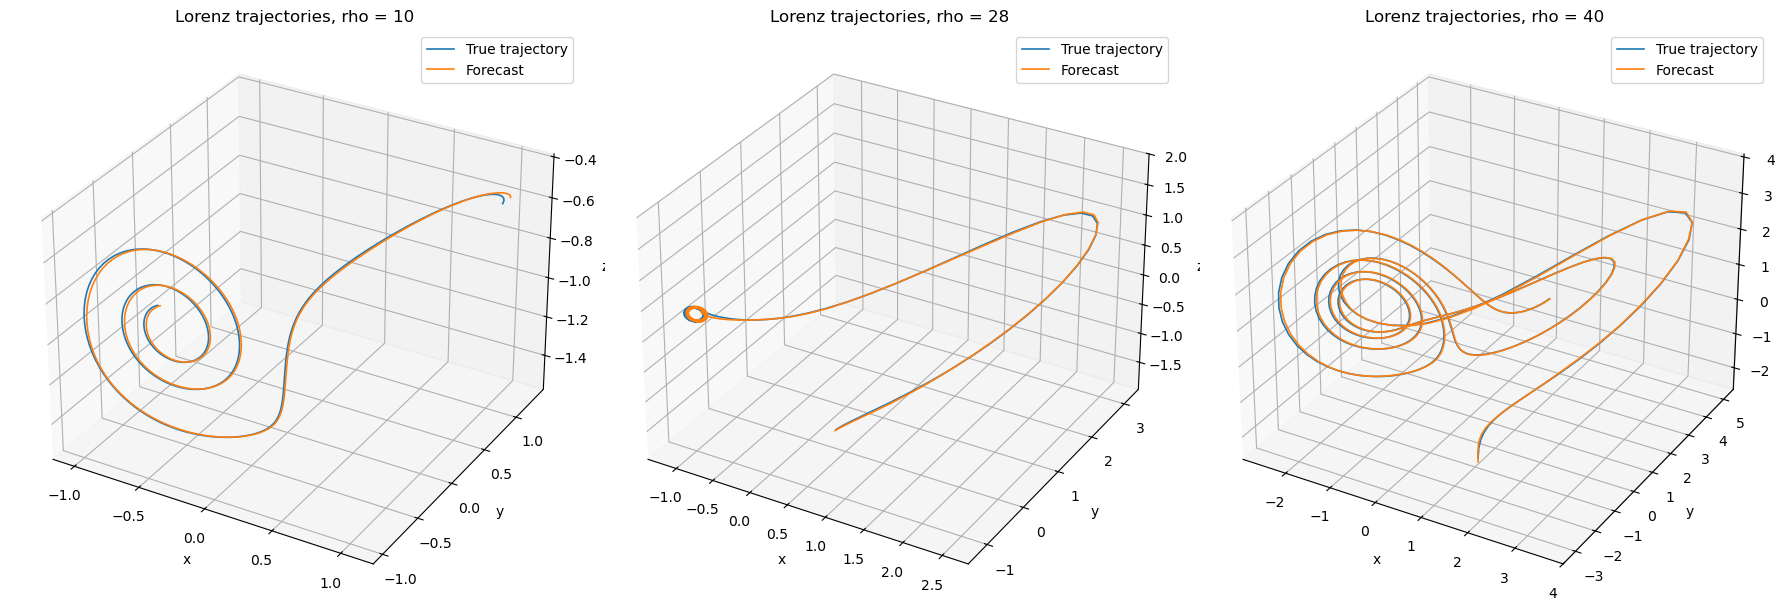

In [34]:
# Compare the fitted output with the original target data.
# Choose one random trajectory per rho
trajectory_indices = [i * n_trajectories_per_rho for i in range(len(rho_train))]
X_lorenz_list = [x_scaler_lorenz.transform(inputs_train[idx]) for idx in trajectory_indices]
Y_lorenz_list = [y_scaler_lorenz.transform(outputs_train[idx]) for idx in trajectory_indices]
y_train_pred_lorenz = [np.asarray(model(X, training=False)) for X in X_lorenz_list]

fig = plt.figure(figsize=(18, 6))

for i in range(len(rho_train)):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    ax.plot(
        Y_lorenz_list[i][:, 0],
        Y_lorenz_list[i][:, 1],
        Y_lorenz_list[i][:, 2],
        linewidth=1.2,
        label="True trajectory",
    )
    ax.plot(
        y_train_pred_lorenz[i][:, 0],
        y_train_pred_lorenz[i][:, 1],
        y_train_pred_lorenz[i][:, 2],
        linewidth=1.2,
        label="Forecast",
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(f"Lorenz trajectories, rho = {rho_train[i]}")
    ax.legend()

plt.tight_layout()
plt.show()

It is seen that the NN is able to perform one-step prediction on the traning data reasonably well. It is now tested if it is able to forecast the training data.

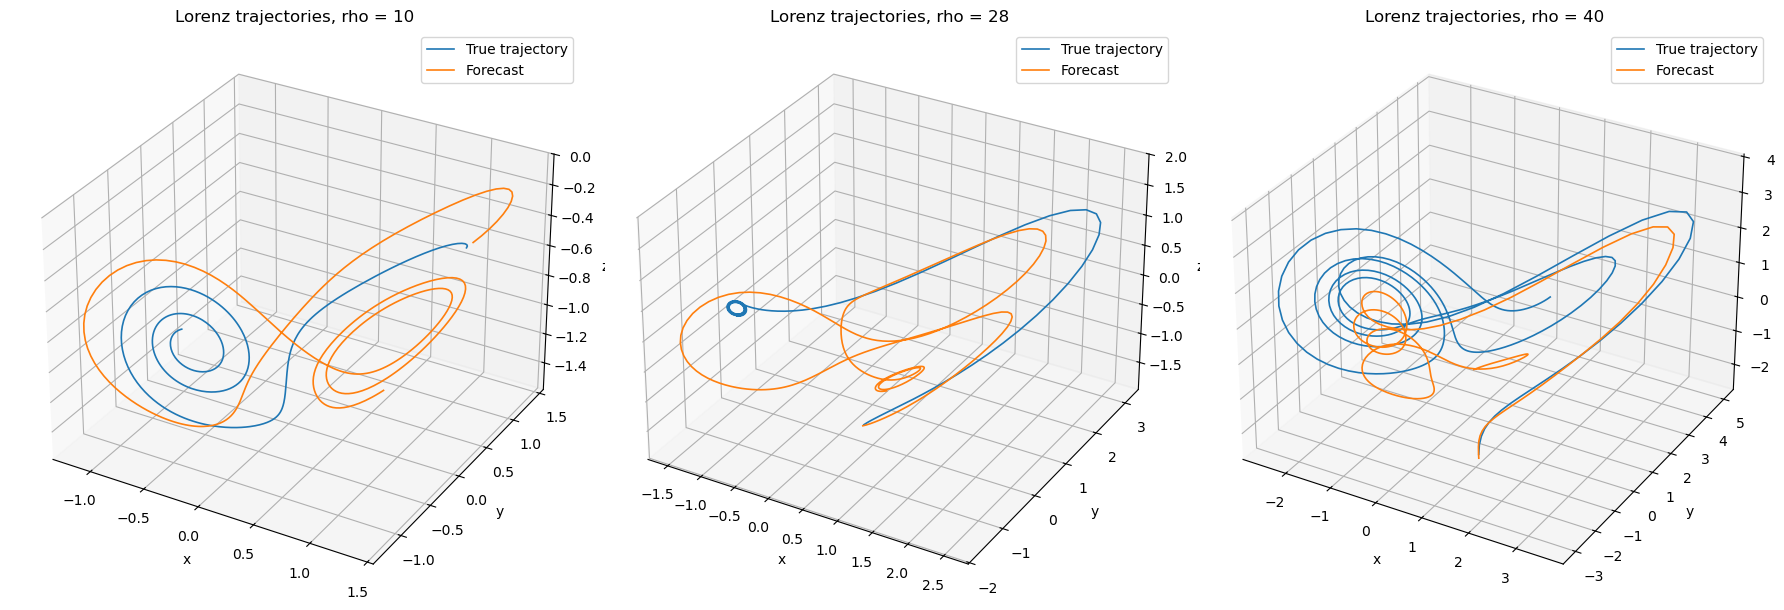

In [37]:
forecasts = []

# Predict one step at a time for each train trajectory
for i in range(len(X_lorenz_list)):
    current = X_lorenz_list[i][0].copy()
    forecast = []
    for _ in range(len(Y_lorenz_list[i])):
        next_state = model.predict(
            current.reshape(1, n_features_lorenz),
            verbose=0,
        )
        forecast.append(next_state[0])
        current = next_state[0]

    forecasts.append(np.array(forecast))

fig = plt.figure(figsize=(18, 6))
for i in range(len(rho_train)):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    ax.plot(
        Y_lorenz_list[i][:, 0],
        Y_lorenz_list[i][:, 1],
        Y_lorenz_list[i][:, 2],
        linewidth=1.2,
        label="True trajectory",
    )
    ax.plot(
        forecasts[i][:, 0],
        forecasts[i][:, 1],
        forecasts[i][:, 2],
        linewidth=1.2,
        label="Forecast",
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(f"Lorenz trajectories, rho = {rho_train[i]}")
    ax.legend()

plt.tight_layout()
plt.show()


It is seen that the model somewhat nicely fits to the training data using one-step prediction, however as soon as the model needs to do forecasting, it becomes quite inaccurate. It may follow some tendencies for each rho, however it is not nearly able to follow the curve as seen for the one-step prediction.

Now the forecasting abilities are tested on the two test datasets, using rho = 17 and rho = 35.

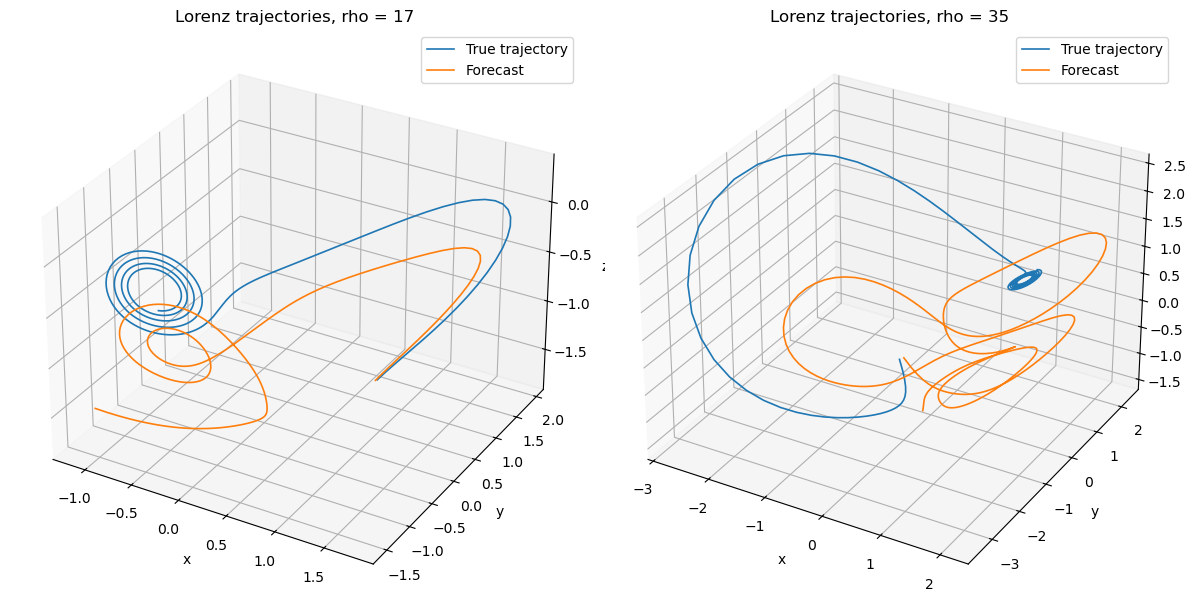

In [40]:
inputs_test_scaled = [x_scaler_lorenz.transform(inputs_test[i]) for i in range(len(inputs_test))]
outputs_test_scaled = [y_scaler_lorenz.transform(outputs_test[i]) for i in range(len(outputs_test))]

forecasts = []
# Predict one step at a time for each test trajectory
for i in range(len(inputs_test_scaled)):
    current = inputs_test_scaled[i][0].copy()
    forecast = []

    for _ in range(len(outputs_test_scaled[i])):
        next_state = model.predict(
            current.reshape(1, n_features_lorenz),
            verbose=0,
        )
        forecast.append(next_state[0])
        current = next_state[0]

    forecasts.append(np.array(forecast))

fig = plt.figure(figsize=(18, 6))
for i in range(len(rho_test)):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")

    ax.plot(
        outputs_test_scaled[i][:, 0],
        outputs_test_scaled[i][:, 1],
        outputs_test_scaled[i][:, 2],
        linewidth=1.2,
        label="True trajectory",
    )
    ax.plot(
        forecasts[i][:, 0],
        forecasts[i][:, 1],
        forecasts[i][:, 2],
        linewidth=1.2,
        label="Forecast",
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(f"Lorenz trajectories, rho = {rho_test[i]}")
    ax.legend()

plt.tight_layout()
plt.show()


It is seen that the NN is better at forecasting the trajectory with rho = 17, than the one with rho = 35. Again the NN is not able to perform truly accurate forecasting, however it does show some tendency of the trajectory. It is however not convincing.

This shows that NNs can be used for forecasting differential equations, however other methods, which are used later in the course, will show to have a clear advantage over pure feedforward NNs. E.g. an exercise using an RNN is also tested for forecasting, which may prove better because of its recuring nature.